In [1]:
import sys

print(sys.executable)

d:\CarePredict-XAI\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.6
NumPy version: 2.4.6


In [3]:
df = pd.read_csv("../data/KaggleV2-May-2016.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (110527, 14)


In [4]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [5]:
df.columns

Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension',
       'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show'],
      dtype='str')

In [6]:
df["No-show"].value_counts()

No-show
No     88208
Yes    22319
Name: count, dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 17.6 MB


In [8]:
df.isnull().sum()

PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

In [9]:
missing = df.isnull().sum()

missing[missing > 0]

Series([], dtype: int64)

In [10]:
df["No-show"].value_counts()

No-show
No     88208
Yes    22319
Name: count, dtype: int64

In [11]:
df["No-show"].value_counts(normalize=True) * 100

No-show
No     79.806744
Yes    20.193256
Name: proportion, dtype: float64

In [12]:
df["Gender"].value_counts()

Gender
F    71840
M    38687
Name: count, dtype: int64

In [13]:
df["No-show"].value_counts()

No-show
No     88208
Yes    22319
Name: count, dtype: int64

In [14]:
df["Scholarship"].value_counts()

Scholarship
0    99666
1    10861
Name: count, dtype: int64

In [15]:
df["SMS_received"].value_counts()

SMS_received
0    75045
1    35482
Name: count, dtype: int64

In [16]:
df["Age"].describe()

count    110527.000000
mean         37.088874
std          23.110205
min          -1.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: Age, dtype: float64

In [17]:
df["Age"].sort_values().head(10)

99832   -1
42893    0
42898    0
42887    0
79548    0
65       0
22192    0
22190    0
22188    0
22187    0
Name: Age, dtype: int64

In [18]:
df["Age"].sort_values(ascending=False).head(10)

63915     115
68127     115
76284     115
97666     115
63912     115
90372     102
58014     102
92084     100
108506    100
79272     100
Name: Age, dtype: int64

In [19]:
print("Hypertension:", df["Hipertension"].unique())
print("Diabetes:", df["Diabetes"].unique())
print("Alcoholism:", df["Alcoholism"].unique())
print("Handicap:", df["Handcap"].unique())
print("Scholarship:", df["Scholarship"].unique())
print("SMS:", df["SMS_received"].unique())

Hypertension: [1 0]
Diabetes: [0 1]
Alcoholism: [0 1]
Handicap: [0 1 2 3 4]
Scholarship: [0 1]
SMS: [0 1]


In [20]:
df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"])
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])

In [21]:
df[["ScheduledDay", "AppointmentDay"]].dtypes

ScheduledDay      datetime64[us, UTC]
AppointmentDay    datetime64[us, UTC]
dtype: object

Days_In_Advance

In [22]:
df["Days_In_Advance"] = (
    df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()
).dt.days

In [23]:
df["Days_In_Advance"].describe()

count    110527.000000
mean         10.183702
std          15.254996
min          -6.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: Days_In_Advance, dtype: float64

In [24]:
df[["ScheduledDay", "AppointmentDay", "Days_In_Advance"]].head()

,ScheduledDay,AppointmentDay,Days_In_Advance
0,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,0
1,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,0
2,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,0
3,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,0
4,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,0


In [25]:
(df["Days_In_Advance"] < 0).sum()

np.int64(5)

In [26]:
df = df.rename(columns={
    "Hipertension": "Hypertension",
    "Handcap": "Handicap"
})

In [27]:
df.columns

Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hypertension',
       'Diabetes', 'Alcoholism', 'Handicap', 'SMS_received', 'No-show',
       'Days_In_Advance'],
      dtype='str')

Convert target into numbers

In [28]:
df["No_show"] = df["No-show"].map({
    "No": 0,
    "Yes": 1
})

In [29]:
df["No_show"].value_counts()

No_show
0    88208
1    22319
Name: count, dtype: int64

In [30]:
df.to_csv("../data/cleaned_appointments.csv", index=False)

# Exploratory Data Analysis

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [32]:
df["No_show"].value_counts()

No_show
0    88208
1    22319
Name: count, dtype: int64

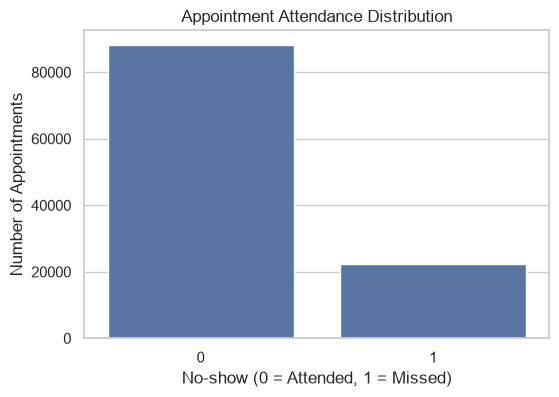

In [33]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="No_show")

plt.title("Appointment Attendance Distribution")
plt.xlabel("No-show (0 = Attended, 1 = Missed)")
plt.ylabel("Number of Appointments")

plt.show()

In [34]:
no_show_percentage = df["No_show"].value_counts(normalize=True) * 100

print(no_show_percentage)

No_show
0    79.806744
1    20.193256
Name: proportion, dtype: float64


In [35]:
print(f"Attended: {no_show_percentage[0]:.2f}%")
print(f"No-show: {no_show_percentage[1]:.2f}%")

Attended: 79.81%
No-show: 20.19%


In [36]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[-1, 12, 18, 30, 45, 60, 75, 120],
    labels=[
        "Child",
        "Teen",
        "Young Adult",
        "Adult",
        "Middle Age",
        "Senior",
        "Elderly"
    ]
)

In [37]:
age_no_show = df.groupby("Age_Group", observed=True)["No_show"].mean() * 100

print(age_no_show)

Age_Group
Child          20.474425
Teen           26.053640
Young Adult    24.712198
Adult          21.371960
Middle Age     17.822167
Senior         14.864301
Elderly        16.135015
Name: No_show, dtype: float64


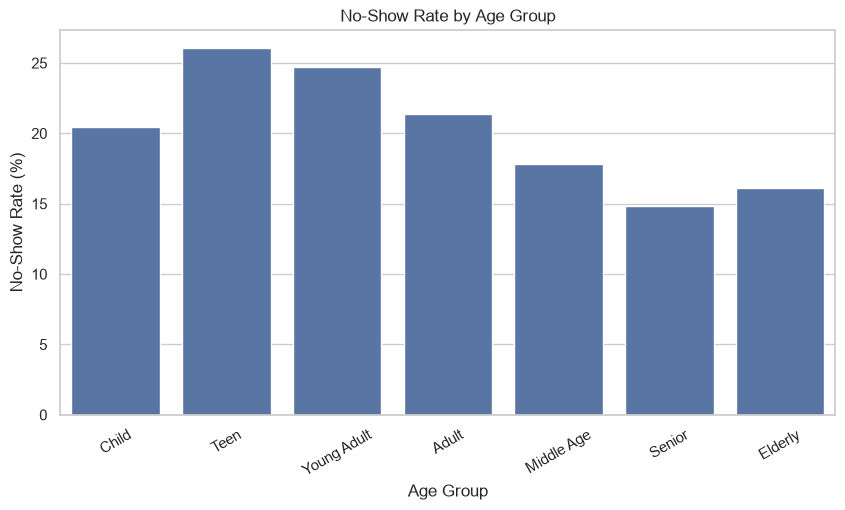

In [38]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=age_no_show.index,
    y=age_no_show.values
)

plt.title("No-Show Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=30)

plt.show()

In [39]:
df["Days_In_Advance"].describe()

count    110527.000000
mean         10.183702
std          15.254996
min          -6.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: Days_In_Advance, dtype: float64

In [40]:
df["AppointmentDay"] - df["ScheduledDay"]

0        -1 days +05:21:52
1        -1 days +07:51:33
2        -1 days +07:40:56
3        -1 days +06:30:29
4        -1 days +07:52:37
                ...       
110522    34 days 14:44:25
110523    34 days 16:32:27
110524    40 days 07:56:08
110525    40 days 08:50:37
110526    40 days 10:29:04
Length: 110527, dtype: timedelta64[us]

In [41]:
df["Days_In_Advance"] = (
    df["AppointmentDay"].dt.normalize()
    - df["ScheduledDay"].dt.normalize()
).dt.days

In [42]:
print("Negative values:", (df["Days_In_Advance"] < 0).sum())

Negative values: 5


#Create waiting-period groups

In [43]:
df["Waiting_Group"] = pd.cut(
    df["Days_In_Advance"],
    bins=[-1, 0, 3, 7, 14, 30, 60, 365],
    labels=[
        "Same Day",
        "1-3 Days",
        "4-7 Days",
        "8-14 Days",
        "15-30 Days",
        "31-60 Days",
        "60+ Days"
    ]
)

In [44]:
waiting_no_show = (
    df.groupby("Waiting_Group", observed=True)["No_show"].mean() * 100
)

print(waiting_no_show)

Waiting_Group
Same Day       4.646941
1-3 Days      22.889267
4-7 Days      25.202741
8-14 Days     30.469854
15-30 Days    32.588797
31-60 Days    34.154292
60+ Days      28.448687
Name: No_show, dtype: float64


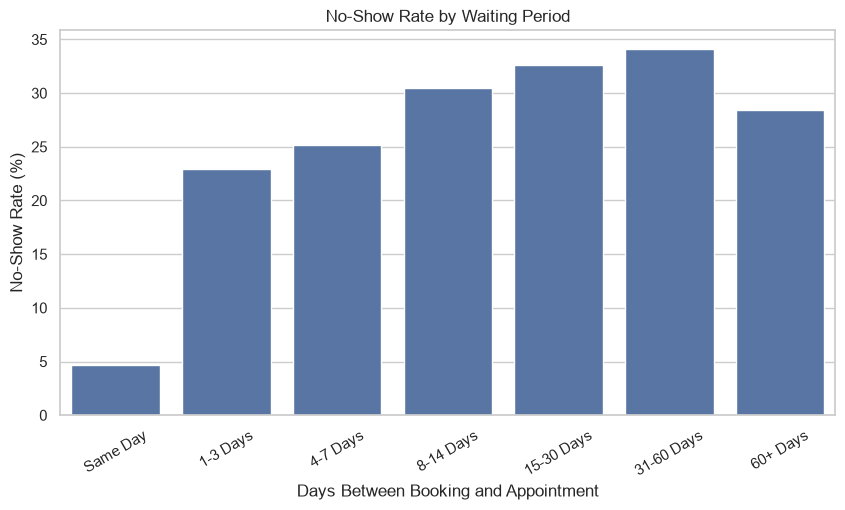

In [45]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=waiting_no_show.index,
    y=waiting_no_show.values
)

plt.title("No-Show Rate by Waiting Period")
plt.xlabel("Days Between Booking and Appointment")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=30)

plt.show()

#SMS Reminder vs No-Show

In [46]:
sms_no_show = (
    df.groupby("SMS_received")["No_show"].mean() * 100
)

print(sms_no_show)

SMS_received
0    16.703311
1    27.574545
Name: No_show, dtype: float64


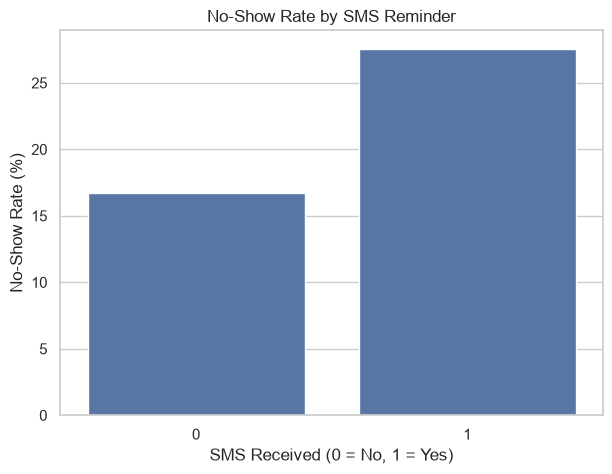

In [47]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=sms_no_show.index,
    y=sms_no_show.values
)

plt.title("No-Show Rate by SMS Reminder")
plt.xlabel("SMS Received (0 = No, 1 = Yes)")
plt.ylabel("No-Show Rate (%)")

plt.show()

In [48]:
#Gender vs No-Show

In [49]:
gender_no_show = (
    df.groupby("Gender")["No_show"].mean() * 100
)

print(gender_no_show)

Gender
F    20.314588
M    19.967948
Name: No_show, dtype: float64


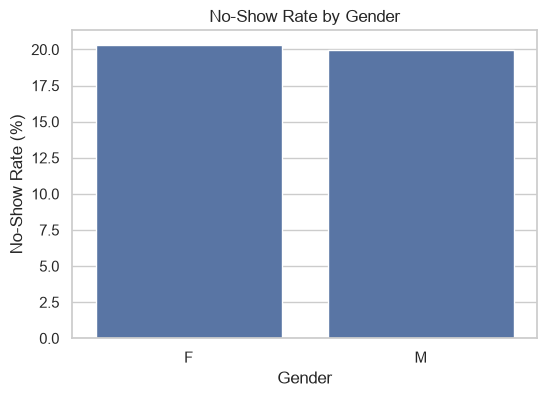

In [50]:
plt.figure(figsize=(6, 4))

sns.barplot(
    x=gender_no_show.index,
    y=gender_no_show.values
)

plt.title("No-Show Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("No-Show Rate (%)")

plt.show()

#Diabetes vs No-Show

In [51]:
diabetes_no_show = (
    df.groupby("Diabetes")["No_show"].mean() * 100
)

print(diabetes_no_show)

Diabetes
0    20.362825
1    18.003273
Name: No_show, dtype: float64


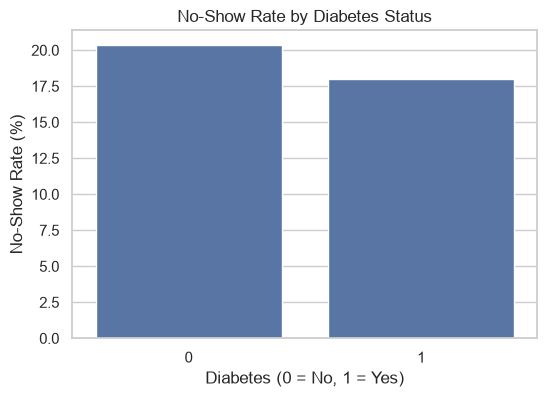

In [52]:
plt.figure(figsize=(6, 4))

sns.barplot(
    x=diabetes_no_show.index,
    y=diabetes_no_show.values
)

plt.title("No-Show Rate by Diabetes Status")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("No-Show Rate (%)")

plt.show()

#Hypertension vs No-Show

In [53]:
hypertension_no_show = (
    df.groupby("Hypertension")["No_show"].mean() * 100
)

print(hypertension_no_show)

Hypertension
0    20.903681
1    17.301959
Name: No_show, dtype: float64


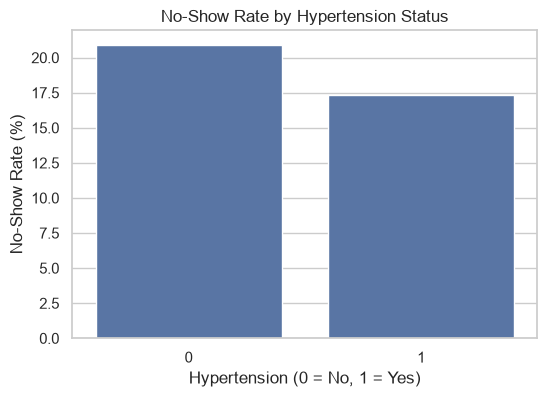

In [54]:
plt.figure(figsize=(6, 4))

sns.barplot(
    x=hypertension_no_show.index,
    y=hypertension_no_show.values
)

plt.title("No-Show Rate by Hypertension Status")
plt.xlabel("Hypertension (0 = No, 1 = Yes)")
plt.ylabel("No-Show Rate (%)")

plt.show()

#Correlation heatmap 🔥

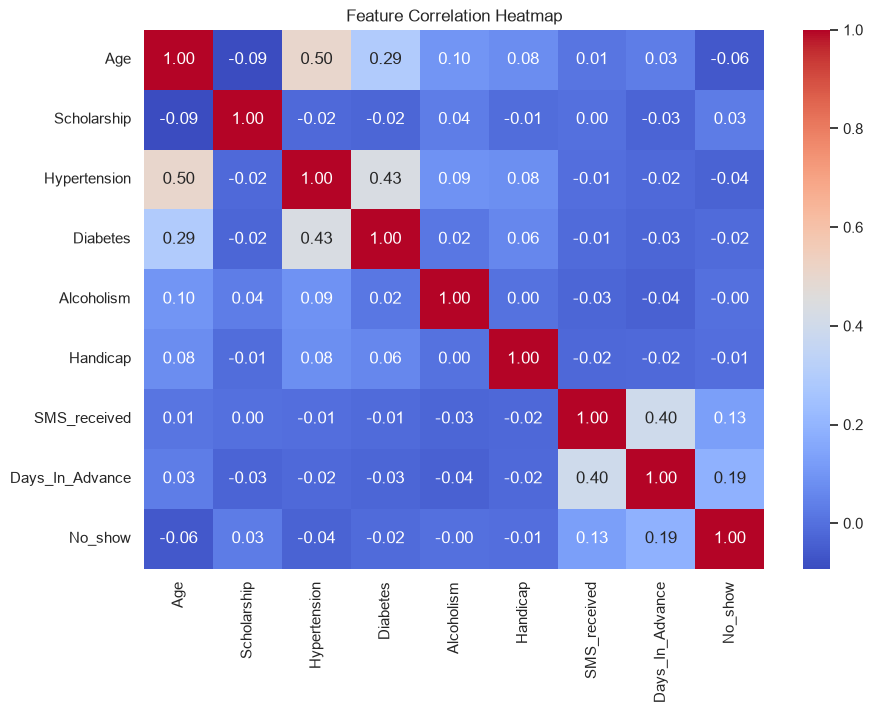

In [55]:
numeric_cols = [
    "Age",
    "Scholarship",
    "Hypertension",
    "Diabetes",
    "Alcoholism",
    "Handicap",
    "SMS_received",
    "Days_In_Advance",
    "No_show"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")

plt.show()

FEATURE ENGINEERING

In [56]:
model_df = df.loc[
    df["Age"].between(0, 120)
    & df["Days_In_Advance"].ge(0)
    & df["No_show"].notna()
].copy()

In [57]:
model_df["Appointment_Weekday"] = (
    model_df["AppointmentDay"].dt.dayofweek
)

In [58]:
model_df["Appointment_Weekday"].value_counts().sort_index()

Appointment_Weekday
0    22713
1    25638
2    25866
3    17246
4    19019
5       39
Name: count, dtype: int64

In [59]:
model_df["Appointment_Month"] = (
    model_df["AppointmentDay"].dt.month
)

In [60]:
model_df["Scheduled_Hour"] = (
    model_df["ScheduledDay"].dt.hour
)

In [61]:
model_df["No_show"]

0         0
1         0
2         0
3         0
4         0
         ..
110522    0
110523    0
110524    0
110525    0
110526    0
Name: No_show, Length: 110521, dtype: int64

In [62]:
model_df["No_show"].value_counts()

No_show
0    88207
1    22314
Name: count, dtype: int64

In [63]:
model_df.columns.tolist()

['PatientId',
 'AppointmentID',
 'Gender',
 'ScheduledDay',
 'AppointmentDay',
 'Age',
 'Neighbourhood',
 'Scholarship',
 'Hypertension',
 'Diabetes',
 'Alcoholism',
 'Handicap',
 'SMS_received',
 'No-show',
 'Days_In_Advance',
 'No_show',
 'Age_Group',
 'Waiting_Group',
 'Appointment_Weekday',
 'Appointment_Month',
 'Scheduled_Hour']

In [64]:
features = [
    "Gender",
    "Age",
    "Scholarship",
    "Hypertension",
    "Diabetes",
    "Alcoholism",
    "Handicap",
    "SMS_received",
    "Days_In_Advance",
    "Appointment_Weekday",
    "Appointment_Month",
    "Scheduled_Hour"
]

X = model_df[features]
y = model_df["No_show"]

In [65]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (110521, 12)
y shape: (110521,)


Convert Gender into numbers

In [66]:
X = pd.get_dummies(
    X,
    columns=["Gender"],
    drop_first=True
)

In [67]:
X.head()

,Age,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,Days_In_Advance,Appointment_Weekday,Appointment_Month,Scheduled_Hour,Gender_M
0,62,0,1,0,0,0,0,0,4,4,18,False
1,56,0,0,0,0,0,0,0,4,4,16,True
2,62,0,0,0,0,0,0,0,4,4,16,False
3,8,0,0,0,0,0,0,0,4,4,17,False
4,56,0,1,1,0,0,0,0,4,4,16,False


In [68]:
print(y.value_counts())

No_show
0    88207
1    22314
Name: count, dtype: int64


In [69]:
print(y.value_counts(normalize=True) * 100)

No_show
0    79.810172
1    20.189828
Name: proportion, dtype: float64


Exploratory grouped split. For the complete grouped and chronological evaluation, calibration, threshold selection, and model artifact generation, run `python -m src.evaluate_model` from the project root.

In [70]:
from sklearn.model_selection import GroupShuffleSplit

In [71]:
groups = model_df.loc[X.index, "PatientId"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

In [72]:
stratify=y

Apply SMOTE

In [73]:
from imblearn.over_sampling import SMOTENC

categorical_columns = [
    "Scholarship", "Hypertension", "Diabetes", "Alcoholism", "Handicap",
    "SMS_received", "Appointment_Weekday", "Appointment_Month",
    "Scheduled_Hour", "Gender_M"
]
categorical_indices = [X_train.columns.get_loc(name) for name in categorical_columns]

In [74]:
smote = SMOTENC(categorical_features=categorical_indices, random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [75]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
No_show
0    70645
1    17796
Name: count, dtype: int64

After SMOTE:
No_show
0    70645
1    70645
Name: count, dtype: int64


Build our first ML model - Logistic Regression baseline.

In [76]:
print("Training shape:", X_train_smote.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target:")
print(y_train_smote.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training shape: (141290, 12)
Testing shape: (22080, 12)

Training target:
No_show
0    70645
1    70645
Name: count, dtype: int64

Testing target:
No_show
0    17562
1     4518
Name: count, dtype: int64


In [77]:
from sklearn.linear_model import LogisticRegression

In [78]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [79]:
log_model.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [80]:
y_pred = log_model.predict(X_test)

In [81]:
y_prob = log_model.predict_proba(X_test)[:, 1]

In [82]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.6621376811594203
Precision: 0.32030295626679695
Recall   : 0.5803452855245684
F1 Score : 0.4127833753148615
ROC-AUC  : 0.6644106235851995


In [83]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[11998  5564]
 [ 1896  2622]]


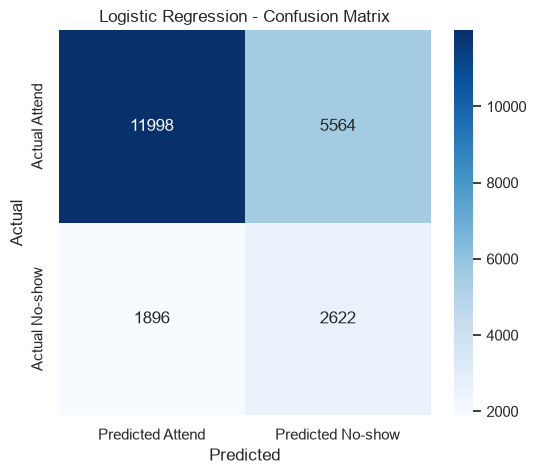

In [84]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Attend", "Predicted No-show"],
    yticklabels=["Actual Attend", "Actual No-show"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [85]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.68      0.76     17562
           1       0.32      0.58      0.41      4518

    accuracy                           0.66     22080
   macro avg       0.59      0.63      0.59     22080
weighted avg       0.75      0.66      0.69     22080



In [86]:
#Step 9 — Random Forest
from sklearn.ensemble import RandomForestClassifier

In [87]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [88]:
rf_model.fit(X_train_smote, y_train_smote)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [89]:
rf_pred = rf_model.predict(X_test)

In [90]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [91]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

Random Forest Results
---------------------
Accuracy : 0.6875452898550725
Precision: 0.3133134702838325
Recall   : 0.44223107569721115
F1 Score : 0.36677374942634233
ROC-AUC  : 0.6802484415045785


In [92]:
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.75      0.79     17562
           1       0.31      0.44      0.37      4518

    accuracy                           0.69     22080
   macro avg       0.58      0.60      0.58     22080
weighted avg       0.73      0.69      0.71     22080



In [93]:
rf_cm = confusion_matrix(y_test, rf_pred)

print("Confusion Matrix:")
print(rf_cm)

Confusion Matrix:
[[13183  4379]
 [ 2520  1998]]


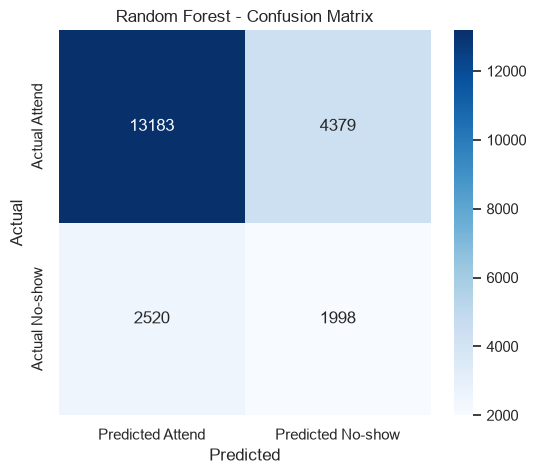

In [94]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Attend", "Predicted No-show"],
    yticklabels=["Actual Attend", "Actual No-show"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [95]:
#Step 10 — XGBoost

In [96]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

In [97]:
xgb_model.fit(X_train_smote, y_train_smote)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [98]:
xgb_pred = xgb_model.predict(X_test)

In [99]:
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

In [100]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)
xgb_roc_auc = roc_auc_score(y_test, xgb_prob)

print("XGBoost Results")
print("----------------")
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)
print("ROC-AUC  :", xgb_roc_auc)

XGBoost Results
----------------
Accuracy : 0.6198369565217391
Precision: 0.31860726319730437
Recall   : 0.7534307215582116
F1 Score : 0.4478358110774898
ROC-AUC  : 0.7270552103043116


In [101]:
#Step 11 — Model Comparison Visualization

In [102]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Logistic Regression metrics
log_accuracy = accuracy_score(y_test, y_pred)
log_precision = precision_score(y_test, y_pred)
log_recall = recall_score(y_test, y_pred)
log_f1 = f1_score(y_test, y_pred)
log_roc_auc = roc_auc_score(y_test, y_prob)

# Random Forest metrics
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

# XGBoost metrics
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)
xgb_roc_auc = roc_auc_score(y_test, xgb_prob)


# Create comparison table
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        log_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        log_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        log_recall,
        rf_recall,
        xgb_recall
    ],
    "F1 Score": [
        log_f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        log_roc_auc,
        rf_roc_auc,
        xgb_roc_auc
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.662138,0.320303,0.580345,0.412783,0.664411
1,Random Forest,0.687545,0.313313,0.442231,0.366774,0.680248
2,XGBoost,0.619837,0.318607,0.753431,0.447836,0.727055


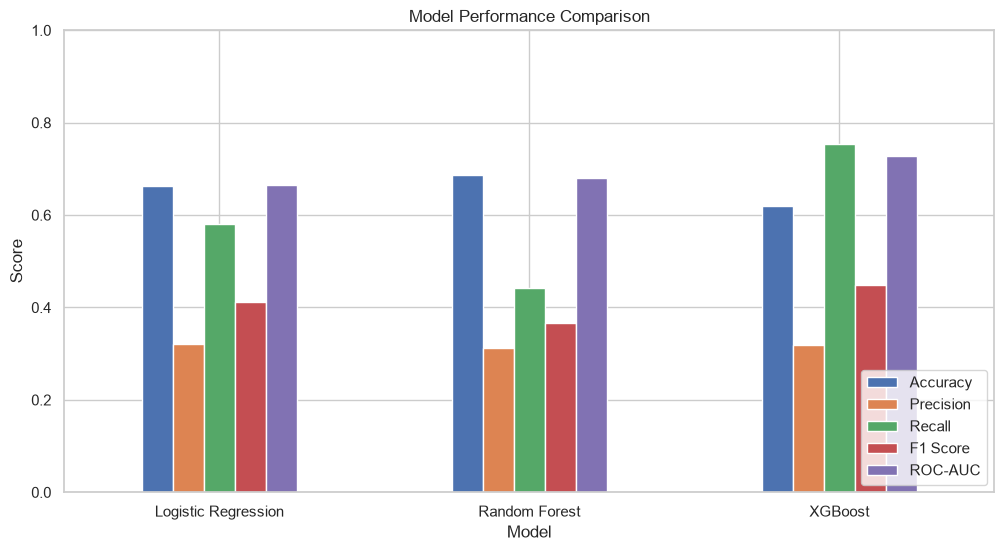

In [103]:
comparison_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [104]:
#Step 12 — Confusion Matrix for XGBoost

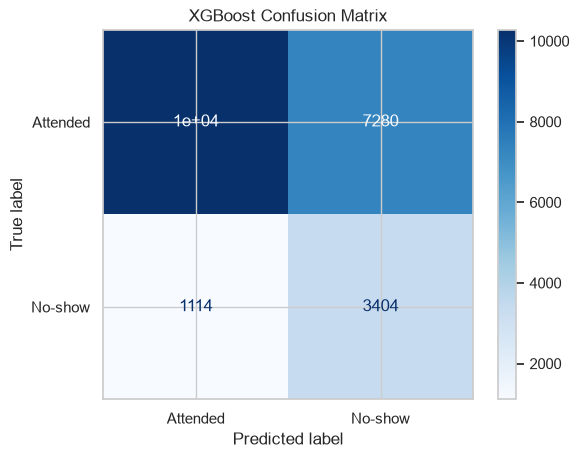

In [105]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred,
    display_labels=["Attended", "No-show"],
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")
plt.show()

In [106]:
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["Attended", "No-show"]
))

              precision    recall  f1-score   support

    Attended       0.90      0.59      0.71     17562
     No-show       0.32      0.75      0.45      4518

    accuracy                           0.62     22080
   macro avg       0.61      0.67      0.58     22080
weighted avg       0.78      0.62      0.66     22080



In [107]:
#Step 13 — SHAP Explainability
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [108]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test)

print("SHAP values shape:", shap_values.shape)
print("Test data shape:", X_test.shape)

SHAP values shape: (22080, 12)
Test data shape: (22080, 12)


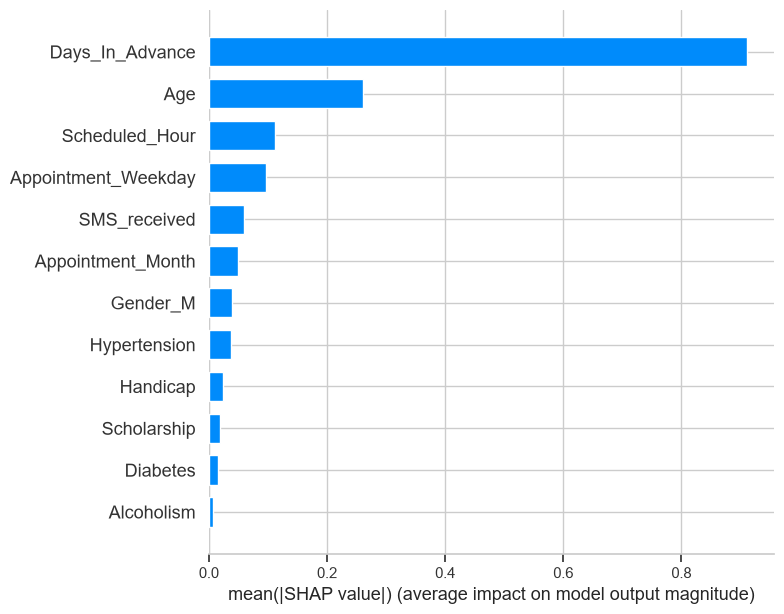

In [109]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

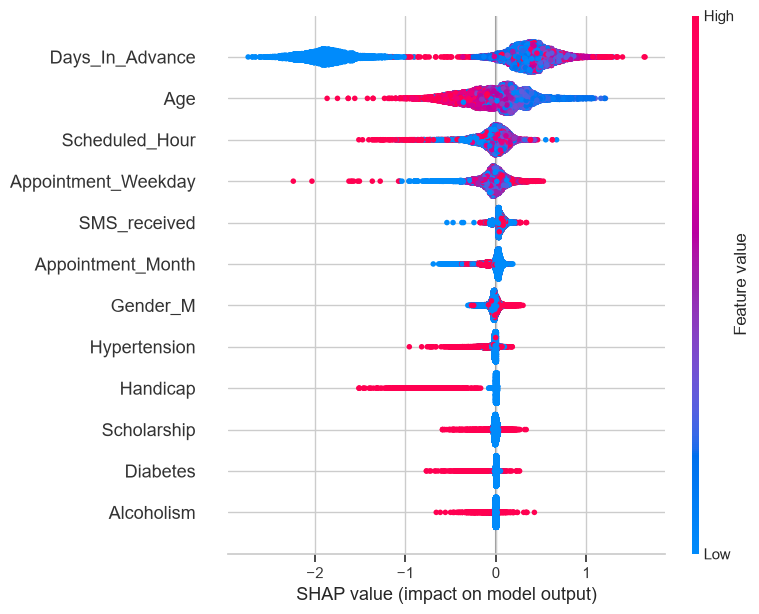

In [110]:
shap.summary_plot(
    shap_values,
    X_test
)

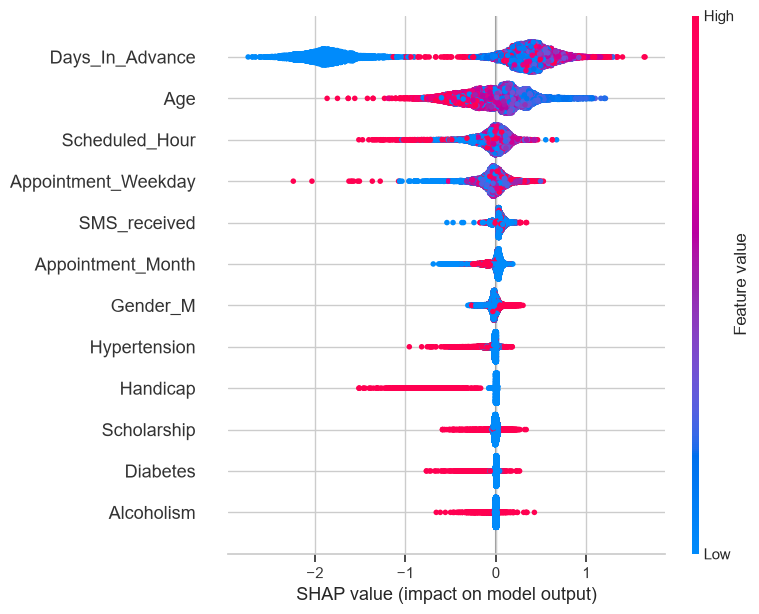

In [111]:
plt.figure()

shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.tight_layout()
plt.savefig(
    "../reports/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [112]:
# Select one patient from the test dataset
patient_index = 0

patient = X_test.iloc[patient_index]

print(patient)

Age                       56
Scholarship                0
Hypertension               1
Diabetes                   1
Alcoholism                 0
Handicap                   0
SMS_received               0
Days_In_Advance            0
Appointment_Weekday        4
Appointment_Month          4
Scheduled_Hour            16
Gender_M               False
Name: 4, dtype: object


In [113]:
patient_prediction = xgb_model.predict(
    X_test.iloc[[patient_index]]
)[0]

patient_probability = xgb_model.predict_proba(
    X_test.iloc[[patient_index]]
)[0][1]

print("Prediction:", patient_prediction)
print("No-show probability:", patient_probability)
print("No-show probability (%):", round(patient_probability * 100, 2))

Prediction: 0
No-show probability: 0.0512219
No-show probability (%): 5.12


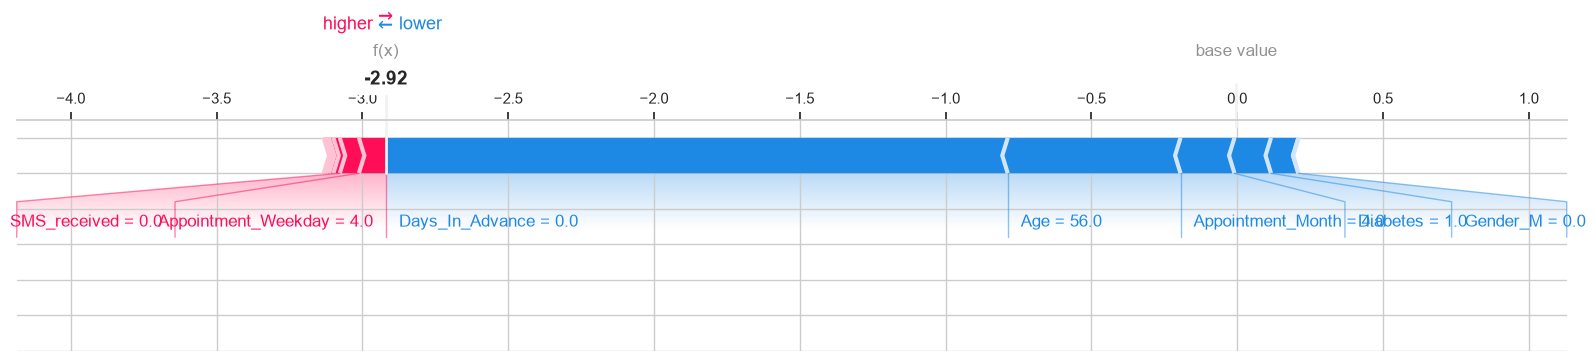

In [114]:
shap.force_plot(
    explainer.expected_value,
    shap_values[patient_index],
    X_test.iloc[patient_index],
    matplotlib=True
)

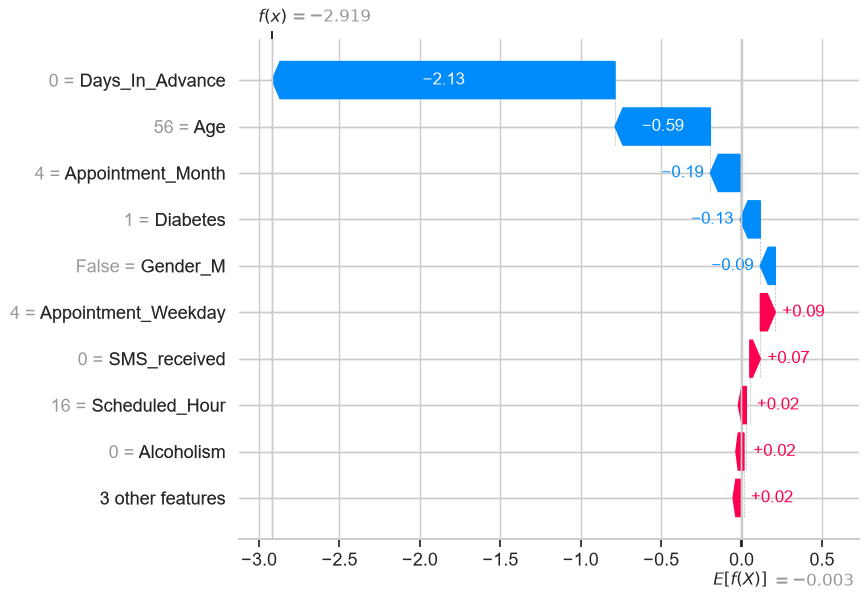

In [115]:
shap_explanation = shap.Explanation(
    values=shap_values[patient_index],
    base_values=explainer.expected_value,
    data=X_test.iloc[patient_index].values,
    feature_names=X_test.columns
)

shap.plots.waterfall(shap_explanation)

In [116]:
patient_shap = pd.DataFrame({
    "Feature": X_test.columns,
    "SHAP_Value": shap_values[patient_index],
    "Feature_Value": X_test.iloc[patient_index].values
})

patient_shap["Absolute_SHAP"] = patient_shap["SHAP_Value"].abs()

patient_shap = patient_shap.sort_values(
    "Absolute_SHAP",
    ascending=False
)

patient_shap.head(5)

,Feature,SHAP_Value,Feature_Value,Absolute_SHAP
7,Days_In_Advance,-2.132215,0,2.132215
0,Age,-0.592509,56,0.592509
9,Appointment_Month,-0.185043,4,0.185043
3,Diabetes,-0.125264,1,0.125264
11,Gender_M,-0.093802,False,0.093802


In [117]:
risk_increasing = patient_shap[
    patient_shap["SHAP_Value"] > 0
].head(5)

risk_reducing = patient_shap[
    patient_shap["SHAP_Value"] < 0
].sort_values(
    "SHAP_Value"
).head(5)

print("Risk-Increasing Factors")
print(risk_increasing[["Feature", "SHAP_Value", "Feature_Value"]])

print("\nRisk-Reducing Factors")
print(risk_reducing[["Feature", "SHAP_Value", "Feature_Value"]])

Risk-Increasing Factors
                Feature  SHAP_Value Feature_Value
8   Appointment_Weekday    0.092895             4
6          SMS_received    0.065542             0
10       Scheduled_Hour    0.021993            16
4            Alcoholism    0.015078             0
2          Hypertension    0.010263             1

Risk-Reducing Factors
              Feature  SHAP_Value Feature_Value
7     Days_In_Advance   -2.132215             0
0                 Age   -0.592509            56
9   Appointment_Month   -0.185043             4
3            Diabetes   -0.125264             1
11           Gender_M   -0.093802         False


In [118]:
#Step 15 — What-If Analysis
def predict_no_show_risk(patient_data):
    probability = xgb_model.predict_proba(patient_data)[0][1]
    return probability

In [119]:
patient_data = X_test.iloc[[patient_index]].copy()

print(patient_data)

   Age  Scholarship  Hypertension  Diabetes  Alcoholism  Handicap  \
4   56            0             1         1           0         0   

   SMS_received  Days_In_Advance  Appointment_Weekday  Appointment_Month  \
4             0                0                    4                  4   

   Scheduled_Hour  Gender_M  
4              16     False  


In [120]:
current_risk = predict_no_show_risk(patient_data)

print("Current No-show Risk:",
      round(current_risk * 100, 2), "%")

Current No-show Risk: 5.12 %


In [121]:
print(
    "Current Days_In_Advance:",
    patient_data["Days_In_Advance"].iloc[0]
)

Current Days_In_Advance: 0


In [122]:
what_if_data = patient_data.copy()

what_if_data["Days_In_Advance"] = 5

what_if_risk = predict_no_show_risk(what_if_data)

print("Original Risk:",
      round(current_risk * 100, 2), "%")

print("What-If Risk:",
      round(what_if_risk * 100, 2), "%")

Original Risk: 5.12 %
What-If Risk: 83.7 %


In [123]:
risk_change = what_if_risk - current_risk

print("Risk Change:",
      round(risk_change * 100, 2),
      "percentage points")

Risk Change: 78.57 percentage points


In [124]:
waiting_periods = [0, 3, 7, 14, 30, 60]

scenario_results = []

for days in waiting_periods:
    scenario = patient_data.copy()
    scenario["Days_In_Advance"] = days
    
    risk = predict_no_show_risk(scenario)
    
    scenario_results.append({
        "Days_In_Advance": days,
        "Predicted_No_Show_Risk": risk * 100
    })

scenario_df = pd.DataFrame(scenario_results)

scenario_df

,Days_In_Advance,Predicted_No_Show_Risk
0,0,5.122190
1,3,43.350052
2,7,51.194424
3,14,48.165653
4,30,41.313068
5,60,42.162167


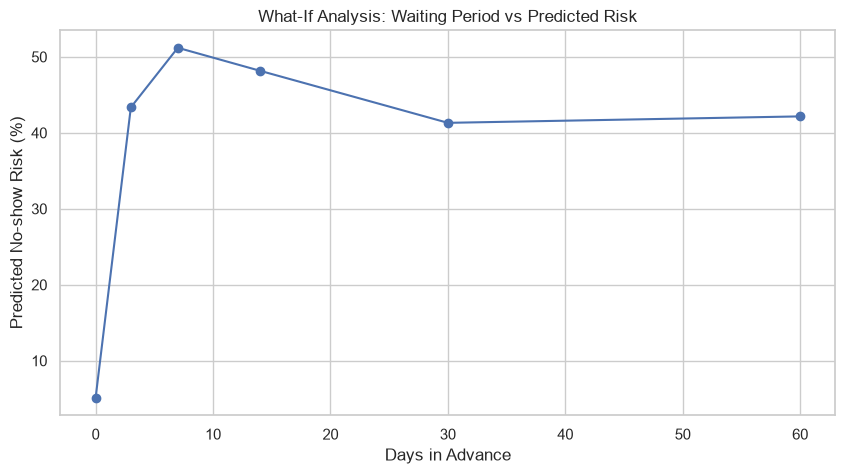

In [125]:
plt.figure(figsize=(10, 5))

plt.plot(
    scenario_df["Days_In_Advance"],
    scenario_df["Predicted_No_Show_Risk"],
    marker="o"
)

plt.xlabel("Days in Advance")
plt.ylabel("Predicted No-show Risk (%)")
plt.title("What-If Analysis: Waiting Period vs Predicted Risk")
plt.grid(True)

plt.show()

In [126]:
sms_scenarios = []

for sms_value in [0, 1]:

    scenario = patient_data.copy()
    scenario["SMS_received"] = sms_value

    risk = predict_no_show_risk(scenario)

    sms_scenarios.append({
        "SMS_received": sms_value,
        "Predicted_No_Show_Risk": risk * 100
    })

sms_df = pd.DataFrame(sms_scenarios)

sms_df

,SMS_received,Predicted_No_Show_Risk
0,0,5.122190
1,1,12.015251


In [127]:
def what_if_prediction(patient_data, feature, new_value):
    
    scenario = patient_data.copy()
    
    scenario[feature] = new_value
    
    risk = xgb_model.predict_proba(scenario)[0][1]
    
    return risk

In [128]:
new_risk = what_if_prediction(
    patient_data,
    "Days_In_Advance",
    7
)

print("What-If No-show Risk:",
      round(new_risk * 100, 2), "%")

What-If No-show Risk: 51.19 %


In [129]:
#Step 16 — Save the XGBoost Model

In [130]:
import joblib

joblib.dump(
    xgb_model,
    "../models/xgboost_model.pkl"
)

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [131]:
feature_names = X_train.columns.tolist()

joblib.dump(
    feature_names,
    "../models/feature_names.pkl"
)

print("Feature names saved successfully!")
print(feature_names)

Feature names saved successfully!
['Age', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMS_received', 'Days_In_Advance', 'Appointment_Weekday', 'Appointment_Month', 'Scheduled_Hour', 'Gender_M']


In [132]:
joblib.dump(
    explainer,
    "../models/shap_explainer.pkl"
)

print("SHAP explainer saved successfully!")

SHAP explainer saved successfully!


In [133]:
loaded_model = joblib.load(
    "../models/xgboost_model.pkl"
)

test_probability = loaded_model.predict_proba(
    X_test.iloc[[0]]
)[0][1]

print(
    "Loaded model test probability:",
    round(test_probability * 100, 2),
    "%"
)

Loaded model test probability: 5.12 %
